## Import thư viện và cấu hình

In [ ]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import wandb
from scipy.stats import skew
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold

SEED = 42
DATA_DIR = Path('.')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WANDB_PROJECT = os.getenv('WANDB_PROJECT', 'house-price-mlp')
WANDB_MODE = os.getenv('WANDB_MODE', 'online')


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('W&B mode:', WANDB_MODE)

Device: cpu
W&B mode: offline


## LOAD DATA

In [2]:
train_raw = pd.read_csv(DATA_DIR / 'train.csv')
test_raw = pd.read_csv(DATA_DIR / 'test.csv')

## PREVIEW

In [3]:
print('Train shape:', train_raw.shape)
print('Test shape :', test_raw.shape)
display(train_raw.head())
display(train_raw.tail())
display(test_raw.head())
display(test_raw.tail())

Train shape: (1460, 81)
Test shape : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
1454,2915,160,RM,21.0,1936,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2006,WD,Normal
1455,2916,160,RM,21.0,1894,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2006,WD,Abnorml
1456,2917,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml
1457,2918,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal
1458,2919,60,RL,74.0,9627,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,11,2006,WD,Normal


## Exploratory Data Analysis

In [4]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Missing values - train: 7829
Missing values - test : 7878
SalePrice skewness: 1.8829


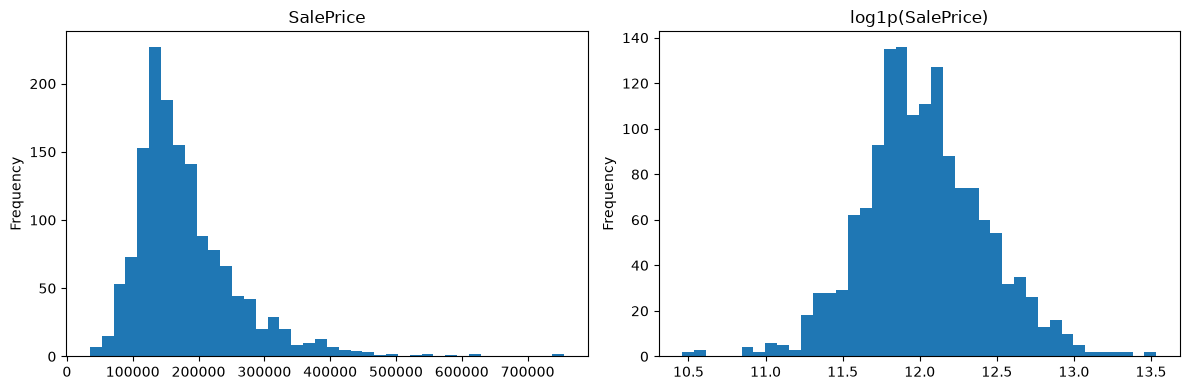

In [5]:
display(train_raw['SalePrice'].describe())
print('Missing values - train:', int(train_raw.isna().sum().sum()))
print('Missing values - test :', int(test_raw.isna().sum().sum()))
print('SalePrice skewness:', round(train_raw['SalePrice'].skew(), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_raw['SalePrice'].plot(kind='hist', bins=40, ax=axes[0], title='SalePrice')
np.log1p(train_raw['SalePrice']).plot(kind='hist', bins=40, ax=axes[1], title='log1p(SalePrice)')
plt.tight_layout()
plt.show()

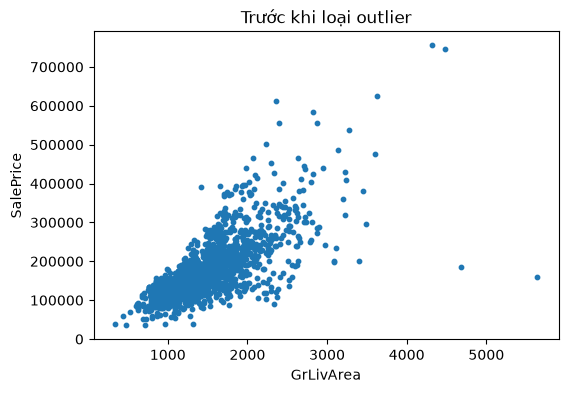

So luong outlier bi loai: 2
Train shape sau khi loai outlier: (1458, 81)


In [6]:
# Outlier kinh điển của Ames Housing (khuyến nghị bởi chính tác giả dataset - De Cock):
# vài căn có GrLivArea rất lớn nhưng SalePrice lại thấp bất thường -> gây nhiễu cho mô hình.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(train_raw['GrLivArea'], train_raw['SalePrice'], s=10)
ax.set_xlabel('GrLivArea')
ax.set_ylabel('SalePrice')
ax.set_title('Trước khi loại outlier')
plt.show()

outlier_mask = (train_raw['GrLivArea'] > 4000) & (train_raw['SalePrice'] < 300000)
print('So luong outlier bi loai:', int(outlier_mask.sum()))
train_raw = train_raw.loc[~outlier_mask].reset_index(drop=True)
print('Train shape sau khi loai outlier:', train_raw.shape)

In [7]:

NONE_CATEGORICAL = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType',
]
ZERO_NUMERIC = [
    'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea',
]


QUALITY_MAP = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
QUALITY_COLUMNS = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
    'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC',
]
BSMT_EXPOSURE_MAP = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
BSMT_FINTYPE_MAP = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
GARAGE_FINISH_MAP = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
FENCE_MAP = {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4}
FUNCTIONAL_MAP = {'Sal': 1, 'Sev': 2, 'Maj2': 3, 'Maj1': 4, 'Mod': 5, 'Min2': 6, 'Min1': 7, 'Typ': 8}


def add_engineered_features(df):
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = (
        df['FullBath'] + 0.5 * df['HalfBath']
        + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    )
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    garage_yr = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df['GarageAge'] = (df['YrSold'] - garage_yr).clip(lower=0)
    df['HasPool'] = (df['PoolArea'] > 0).astype(np.float32)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(np.float32)
    df['HasGarage'] = (df['GarageArea'].fillna(0) > 0).astype(np.float32)
    df['HasBsmt'] = (df['TotalBsmtSF'].fillna(0) > 0).astype(np.float32)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(np.float32)
    for col in ['HouseAge', 'RemodAge', 'GarageAge']:
        df[col] = df[col].clip(lower=0)
    return df


def prepare_features(train_df, test_df, skew_threshold=0.75):
    train = train_df.copy()
    test = test_df.copy()
    y = np.log1p(train.pop('SalePrice').astype('float32').to_numpy())
    test_ids = test['Id'].to_numpy()

    combined = pd.concat([train, test], ignore_index=True).drop(columns=['Id'])
    n_train = len(train)


    for col in NONE_CATEGORICAL:
        combined[col] = combined[col].fillna('None')
    for col in ZERO_NUMERIC:
        combined[col] = combined[col].fillna(0)

    combined['LotFrontage'] = combined.groupby('Neighborhood')['LotFrontage'].transform(
        lambda s: s.fillna(s.median())
    )
    combined['LotFrontage'] = combined['LotFrontage'].fillna(combined['LotFrontage'].median())

  
    categorical_all = combined.select_dtypes(include=['object']).columns
    numeric_all = combined.select_dtypes(exclude=['object']).columns
    for column in numeric_all:
        if combined[column].isna().any():
            combined[column] = combined[column].fillna(combined[column].median())
    for column in categorical_all:
        if combined[column].isna().any():
            mode = combined[column].mode(dropna=True)
            combined[column] = combined[column].fillna(mode.iloc[0] if not mode.empty else 'Missing')

  
    combined = add_engineered_features(combined)

    for col in QUALITY_COLUMNS:
        combined[col] = combined[col].map(QUALITY_MAP).astype(np.float32)
    combined['BsmtExposure'] = combined['BsmtExposure'].map(BSMT_EXPOSURE_MAP).astype(np.float32)
    combined['BsmtFinType1'] = combined['BsmtFinType1'].map(BSMT_FINTYPE_MAP).astype(np.float32)
    combined['BsmtFinType2'] = combined['BsmtFinType2'].map(BSMT_FINTYPE_MAP).astype(np.float32)
    combined['GarageFinish'] = combined['GarageFinish'].map(GARAGE_FINISH_MAP).astype(np.float32)
    combined['Fence'] = combined['Fence'].map(FENCE_MAP).astype(np.float32)
    combined['Functional'] = combined['Functional'].map(FUNCTIONAL_MAP).astype(np.float32)

 
    remaining_categorical = combined.select_dtypes(include=['object']).columns
    combined = pd.get_dummies(combined, columns=list(remaining_categorical), dtype=np.float32)

  
    numeric_cols = combined.select_dtypes(include=[np.number]).columns
    skewed = combined[numeric_cols].apply(lambda s: skew(s.astype('float64')))
    skewed_cols = skewed[(skewed.abs() > skew_threshold) & (combined[skewed.index].min() >= 0)].index
    for col in skewed_cols:
        combined[col] = np.log1p(combined[col])

    values = combined.to_numpy(dtype=np.float32)
    mean = values[:n_train].mean(axis=0)
    std = values[:n_train].std(axis=0)
    std[std < 1e-8] = 1.0
    values = (values - mean) / std
    return values[:n_train], values[n_train:], y, test_ids


X, X_test, y, test_ids = prepare_features(train_raw, test_raw)
print('So dac trung sau xu ly:', X.shape[1])
print(X.shape, X_test.shape)

/tmp/ipykernel_19338/1261117588.py:66: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_all = combined.select_dtypes(include=['object']).columns
/tmp/ipykernel_19338/1261117588.py:89: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-

So dac trung sau xu ly: 242
(1458, 242) (1459, 242)


## Modeling: MLP bằng PyTorch

In [8]:
class HousePriceMLP(torch.nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = torch.nn.Sequential(
            torch.nn.Linear(input_size, 256),
            torch.nn.GELU(),
            torch.nn.BatchNorm1d(256),
            torch.nn.Dropout(0.30),
            torch.nn.Linear(256, 128),
            torch.nn.GELU(),
            torch.nn.BatchNorm1d(128),
            torch.nn.Dropout(0.20),
            torch.nn.Linear(128, 64),
            torch.nn.GELU(),
            torch.nn.BatchNorm1d(64),
            torch.nn.Dropout(0.10),
            torch.nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


def evaluate(model, x, y):
    model.eval()
    with torch.no_grad():
        prediction = model(x).cpu().numpy()
    actual = y.cpu().numpy()
    rmse = float(np.sqrt(mean_squared_error(actual, prediction)))
    mae = float(mean_absolute_error(actual, prediction))
    return rmse, mae, prediction


print(HousePriceMLP(X.shape[1]))

HousePriceMLP(
  (network): Sequential(
    (0): Linear(in_features=242, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): GELU(approximate='none')
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): GELU(approximate='none')
    (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): Dropout(p=0.1, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [9]:
N_FOLDS = 5
EPOCHS = 150
PATIENCE = 20
BATCH_SIZE = 128

if wandb.run is not None:
    wandb.finish()

wandb_run = wandb.init(
    project=WANDB_PROJECT,
    mode=WANDB_MODE,
    config={
        'seed': SEED,
        'n_folds': N_FOLDS,
        'epochs': EPOCHS,
        'patience': PATIENCE,
        'batch_size': BATCH_SIZE,
        'device': str(DEVICE),
    },
    name='mlp-5fold',
    settings=wandb.Settings(init_timeout=30),
)

kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
X_test_t = torch.from_numpy(X_test).to(DEVICE)

oof_predictions = np.zeros(len(X))
test_predictions = np.zeros((N_FOLDS, len(X_test)))
fold_histories = []
fold_best_rmse = []

for fold, (train_idx, valid_idx) in enumerate(kfold.split(X), start=1):
    set_seed(SEED + fold)
    X_train_t = torch.from_numpy(X[train_idx]).to(DEVICE)
    y_train_t = torch.from_numpy(y[train_idx]).to(DEVICE)
    X_valid_t = torch.from_numpy(X[valid_idx]).to(DEVICE)
    y_valid_t = torch.from_numpy(y[valid_idx]).to(DEVICE)

    model = HousePriceMLP(X.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    criterion = torch.nn.MSELoss()
    steps_per_epoch = max(1, (len(X_train_t) + BATCH_SIZE - 1) // BATCH_SIZE)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=2e-3, epochs=EPOCHS, steps_per_epoch=steps_per_epoch
    )

    best_rmse = float('inf')
    best_state = None
    best_valid_pred = None
    wait = 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        permutation = torch.randperm(len(X_train_t), device=DEVICE)
        batch_losses = []
        for indices in permutation.split(BATCH_SIZE):
            optimizer.zero_grad()
            loss = criterion(model(X_train_t[indices]), y_train_t[indices])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            scheduler.step()
            batch_losses.append(float(loss.detach().cpu()))

        valid_rmse, valid_mae, valid_pred = evaluate(model, X_valid_t, y_valid_t)
        train_loss = float(np.mean(batch_losses))
        current_lr = float(optimizer.param_groups[0]['lr'])
        history.append({
            'fold': fold, 'epoch': epoch,
            'train_loss': train_loss,
            'valid_rmse_log': valid_rmse, 'valid_mae_log': valid_mae,
        })
        wandb.log({
            'fold': fold,
            'epoch': epoch,
            'train_loss': train_loss,
            'valid_rmse_log': valid_rmse,
            'valid_mae_log': valid_mae,
            'learning_rate': current_lr,
        })

        if valid_rmse < best_rmse - 1e-5:
            best_rmse = valid_rmse
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_valid_pred = valid_pred
            wait = 0
        else:
            wait += 1
        if wait >= PATIENCE:
            break

    model.load_state_dict(best_state)
    oof_predictions[valid_idx] = best_valid_pred
    with torch.no_grad():
        model.eval()
        test_predictions[fold - 1] = model(X_test_t).cpu().numpy()

    fold_histories.append(pd.DataFrame(history))
    fold_best_rmse.append(best_rmse)
    wandb.log({
        f'fold_{fold}_best_rmse_log': best_rmse,
        f'fold_{fold}_epochs': len(history),
    })
    print(f'Fold {fold}/{N_FOLDS} | best valid RMSE (log) = {best_rmse:.5f} | epochs = {len(history)}')

oof_rmse = float(np.sqrt(mean_squared_error(y, oof_predictions)))
oof_mae = float(mean_absolute_error(y, oof_predictions))
wandb.log({
    'mean_fold_valid_rmse_log': float(np.mean(fold_best_rmse)),
    'std_fold_valid_rmse_log': float(np.std(fold_best_rmse)),
    'oof_rmse_log': oof_rmse,
    'oof_mae_log': oof_mae,
})
print('\nMean fold RMSE :', round(float(np.mean(fold_best_rmse)), 5), '+/-', round(float(np.std(fold_best_rmse)), 5))
print('OOF RMSE (log) :', round(oof_rmse, 5))
print('OOF MAE (log)  :', round(oof_mae, 5))

Fold 1/5 | best valid RMSE (log) = 0.18182 | epochs = 89
Fold 2/5 | best valid RMSE (log) = 0.14309 | epochs = 127
Fold 3/5 | best valid RMSE (log) = 0.13736 | epochs = 150
Fold 4/5 | best valid RMSE (log) = 0.14763 | epochs = 117
Fold 5/5 | best valid RMSE (log) = 0.18107 | epochs = 84

Mean fold RMSE : 0.1582 +/- 0.01926
OOF RMSE (log) : 0.15936
OOF MAE (log)  : 0.11225


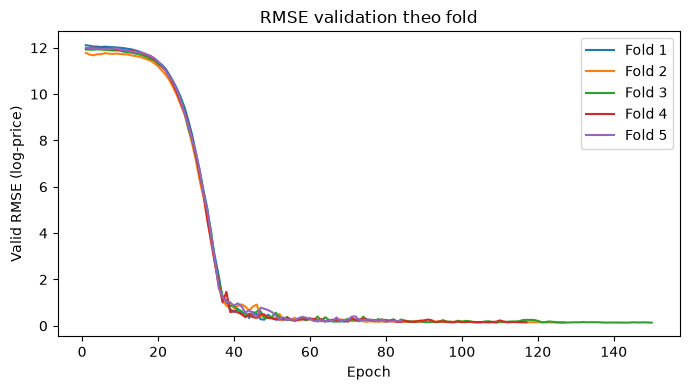

In [10]:
history_df = pd.concat(fold_histories, ignore_index=True)
fig, ax = plt.subplots(figsize=(7, 4))
for fold, group in history_df.groupby('fold'):
    ax.plot(group['epoch'], group['valid_rmse_log'], label=f'Fold {fold}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Valid RMSE (log-price)')
ax.set_title('RMSE validation theo fold')
ax.legend()
plt.tight_layout()
plt.show()

## Evaluation và tạo submission



In [11]:
test_prediction_log = test_predictions.mean(axis=0)

submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': np.expm1(test_prediction_log),
})
submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
history_df.to_csv(OUTPUT_DIR / 'history.csv', index=False)
np.save(OUTPUT_DIR / 'oof_predictions.npy', oof_predictions)

metrics = {
    'device': str(DEVICE),
    'seed': SEED,
    'n_folds': N_FOLDS,
    'features_after_encoding': int(X.shape[1]),
    'mean_fold_valid_rmse_log': float(np.mean(fold_best_rmse)),
    'std_fold_valid_rmse_log': float(np.std(fold_best_rmse)),
    'oof_rmse_log': oof_rmse,
    'oof_mae_log': oof_mae,
    'submission_rows': len(submission),
}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
wandb.log(metrics)
wandb.summary.update(metrics)
wandb.save(str(OUTPUT_DIR / 'history.csv'))
wandb.save(str(OUTPUT_DIR / 'metrics.json'))
wandb.finish()

assert list(submission.columns) == ['Id', 'SalePrice']
assert len(submission) == len(test_raw)
assert submission.isna().sum().sum() == 0
assert (submission['SalePrice'] > 0).all()

print(json.dumps(metrics, indent=2))
display(submission.head())
print('Submission validation: OK')

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▂▃▃▃▃▄▄▂▃▅▆▇▇▁▂▄▅▅▅▆▇▇█▁▃▄▅▅▆▆▇▁▁▂▃▃▄▄▅
features_after_encoding,▁
fold,▁▁▁▁▁▁▁▁▁▁▃▃▃▃▃▃▃▃▃▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆████
fold_1_best_rmse_log,▁
fold_1_epochs,▁
fold_2_best_rmse_log,▁
fold_2_epochs,▁
fold_3_best_rmse_log,▁
fold_3_epochs,▁
fold_4_best_rmse_log,▁
+14,...


{
  "device": "cpu",
  "seed": 42,
  "n_folds": 5,
  "features_after_encoding": 242,
  "mean_fold_valid_rmse_log": 0.15819548061918814,
  "std_fold_valid_rmse_log": 0.01926032581605006,
  "oof_rmse_log": 0.15935548740606664,
  "oof_mae_log": 0.11224578731835133,
  "submission_rows": 1459
}


,Id,SalePrice
0,1461,124308.937049
1,1462,151524.114196
2,1463,185506.926396
3,1464,196249.266988
4,1465,198533.140025


Submission validation: OK
